# Approach 1: SBERT feed-forward neural network

This notebook uses task text and model details to estimate how likely an AI model is to answer correctly. It includes the original prompt-split experiment, LOBO evaluation, and the final model trained on all eligible binary responses. The saved results are shown by default.

In [1]:
from pathlib import Path
import os
import sys
import json

os.environ['KERAS_BACKEND'] = 'torch'
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'dl-project']
REPO = next((path for path in candidates if (path / 'dharaneesh/experiments.py').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Open Jupyter from dl-project or dharaneesh.')
sys.path.insert(0, str(REPO))
DATA_DIR = Path(os.environ.get('AIMS_DATA_DIR', str(REPO.parent)))
ENCODER_DIR = os.environ.get('AIMS_ENCODER_DIR')
print('Python:', sys.executable)
print('Data:', DATA_DIR)

Python: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\.venv-approach1\Scripts\python.exe
Data: C:\Users\dhara\Downloads\aims\aims\data\measurement-db


## Training settings

SBERT turns each task into a numerical vector, which we combine with model details and a few text statistics. The FNN has two hidden layers with 64 and 16 neurons and outputs a probability between 0 and 1. Dropout (0.35) and L2 regularization (0.0001) help reduce overfitting. This run uses Brier loss; set `LOSS = 'bce'` to try binary cross-entropy instead.

In [2]:
RUN_NEW_TRAINING = False
RUN_NAME = 'my_fnn_brier_01'
LOSS = 'brier'
EPOCHS = 20
SEED = 42
REBUILD_ZIP = False

## Prompt-split experiment

The first experiment used binary responses from Multi-SWE-Bench, REAL, ResearchCodeBench, and SWE-rebench. We split task prompts 80/20 for training and validation, keeping responses to the same prompt together. Early stopping kept the model with the lowest validation Brier score. Set `RUN_NEW_TRAINING = True` and choose a new run name to repeat this experiment; it will not replace the final submission.

In [3]:
if RUN_NEW_TRAINING:
    from dharaneesh.experiments import train_fnn_submission
    run_dir = train_fnn_submission(
        DATA_DIR, RUN_NAME, LOSS, EPOCHS, SEED, ENCODER_DIR, publish=False
    )
else:
    run_dir = REPO / 'dharaneesh/results'
    print('Displaying the recorded prompt-split experiment.')

Displaying the recorded prompt-split experiment.


In [4]:
import pandas as pd
from IPython.display import Image, display

history = pd.read_csv(run_dir / 'fnn_history.csv')
summary = json.loads((run_dir / 'fnn_summary.json').read_text())
assert summary['config']['method']['estimator'] == 'fnn'
assert summary['config']['adaptation_precision'] is None
for row in history.to_dict('records'):
    print(f"Epoch {int(row['epoch'])}: training Brier={row['brier_score']:.4f}, "
          f"validation Brier={row['val_pair_brier']:.4f}, "
          f"validation accuracy={row['val_accuracy']:.4f}")
display(history)
print('Best epoch:', summary['best_epoch'])

Epoch 1: training Brier=0.1947, validation Brier=0.1774, validation accuracy=0.7058
Epoch 2: training Brier=0.1681, validation Brier=0.1658, validation accuracy=0.7474
Epoch 3: training Brier=0.1572, validation Brier=0.1626, validation accuracy=0.7561
Epoch 4: training Brier=0.1487, validation Brier=0.1609, validation accuracy=0.7613
Epoch 5: training Brier=0.1424, validation Brier=0.1615, validation accuracy=0.7616
Epoch 6: training Brier=0.1373, validation Brier=0.1612, validation accuracy=0.7618
Epoch 7: training Brier=0.1330, validation Brier=0.1616, validation accuracy=0.7597
Epoch 8: training Brier=0.1292, validation Brier=0.1602, validation accuracy=0.7660
Epoch 9: training Brier=0.1269, validation Brier=0.1608, validation accuracy=0.7632
Epoch 10: training Brier=0.1248, validation Brier=0.1613, validation accuracy=0.7623
Epoch 11: training Brier=0.1221, validation Brier=0.1619, validation accuracy=0.7673
Epoch 12: training Brier=0.1200, validation Brier=0.1640, validation accur

,accuracy,brier_score,loss,val_accuracy,val_brier_score,val_loss,val_pair_brier,epoch
0,0.720542,0.194746,0.205912,0.705788,0.177358,0.187004,0.177357,1
1,0.738358,0.168110,0.177314,0.747439,0.165810,0.174724,0.165810,2
2,0.769884,0.157205,0.166078,0.756122,0.162626,0.171471,0.162626,3
3,0.786756,0.148695,0.157631,0.761326,0.160936,0.169938,0.160936,4
4,0.800359,0.142368,0.151532,0.761579,0.161508,0.170830,0.161508,5
5,0.809699,0.137253,0.146747,0.761820,0.161159,0.170797,0.161159,6
6,0.818053,0.132955,0.142758,0.759692,0.161593,0.171522,0.161593,7
7,0.824009,0.129173,0.139272,0.766031,0.160199,0.170416,0.160199,8
8,0.827914,0.126895,0.137227,0.763250,0.160792,0.171267,0.160792,9
9,0.830593,0.124762,0.135341,0.762271,0.161306,0.171981,0.161306,10


Best epoch: 8


## Validation results

A lower Brier score means better probability predictions. Accuracy counts correct predictions using 0.5 as the cutoff. The graphs give each model-benchmark pair equal weight, while the summary accuracy gives each response equal weight. The Brier graph excludes the L2 penalty. These validation results helped us choose the model; they are not a separate test or competition score.

,row_brier,pair_brier,accuracy,row_ece,pairs,rows
0,0.193065,0.160199,0.664344,0.068767,147,26977


Training rows: 109305
Validation rows: 26977


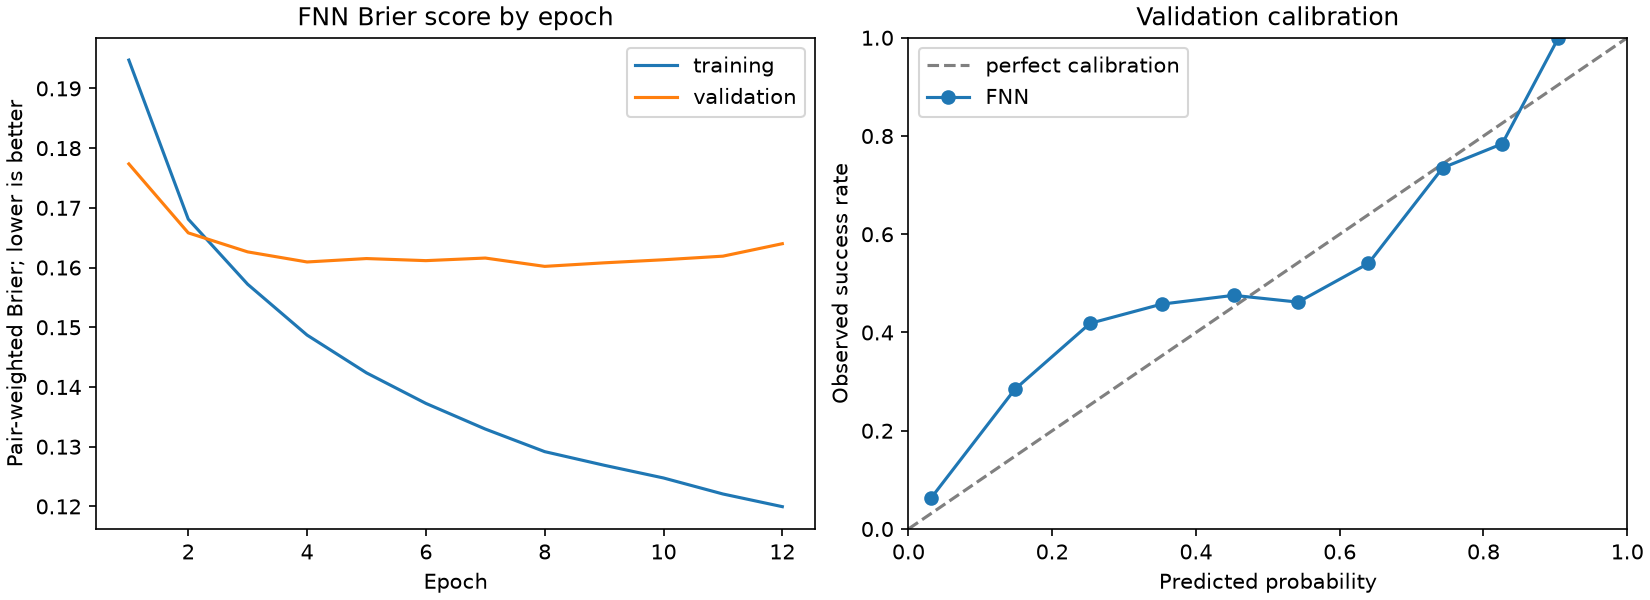

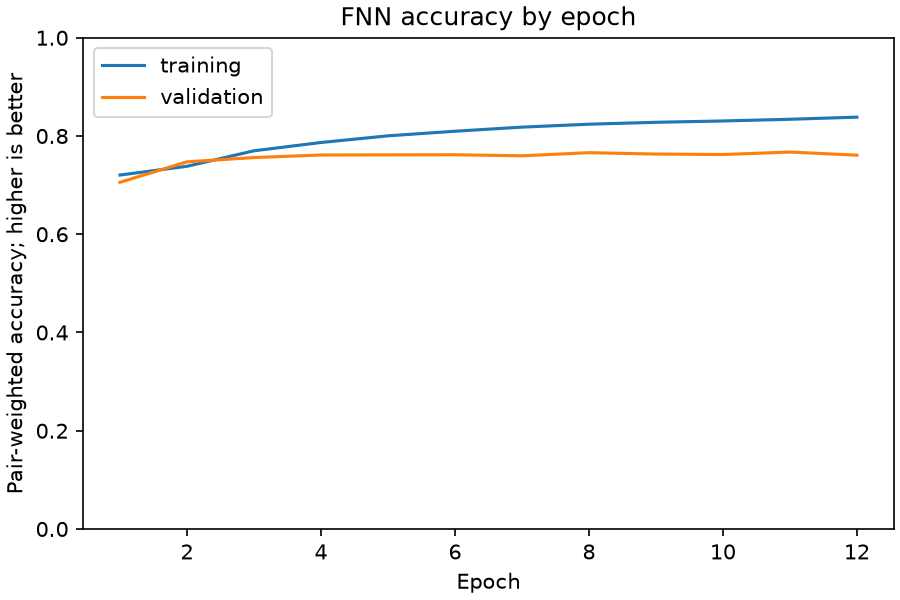

In [5]:
display(pd.DataFrame([summary['validation']]))
print('Training rows:', summary['training_rows'])
print('Validation rows:', summary['validation_rows'])
display(Image(filename=str(run_dir / 'fnn_training.png')))
display(Image(filename=str(run_dir / 'fnn_accuracy.png')))

## Leave-one-benchmark-out evaluation

Here we check whether the same FNN can predict results on a benchmark it has not trained on. Each run holds out one of the four binary benchmarks and trains a fresh model on the other three. A separate 20% prompt split within those three benchmarks is used for early stopping. Matching held-out prompts are also removed from training.

The saved results are shown below. To repeat the experiment, set `RUN_NEW_LOBO = True` and choose a new run name.

In [6]:
RUN_NEW_LOBO = False
LOBO_RUN_NAME = 'fnn_lobo_20261019_02'

if RUN_NEW_LOBO:
    from dharaneesh.lobo import run_lobo
    run_lobo(DATA_DIR, LOBO_RUN_NAME, epochs=20, seed=42, encoder_dir=ENCODER_DIR)

lobo_dir = REPO / 'dharaneesh/results/lobo'
lobo_summary = json.loads((lobo_dir / 'summary.json').read_text())
lobo_scores = pd.read_csv(lobo_dir / 'fold_scores.csv')
print('Held-out benchmark results: equal-pair Brier, lower is better')
display(lobo_scores.pivot(index='held_out', columns='predictor', values='pair_brier').round(4))
print('Overall averages')
display(pd.DataFrame(lobo_summary['aggregate']).T[
    ['pair_brier', 'benchmark_mean_brier', 'row_brier', 'row_accuracy']
].round(4))
print('Selected epochs:', {fold['held_out']: fold['best_epoch'] for fold in lobo_summary['folds']})

Held-out benchmark results: equal-pair Brier, lower is better


predictor,Constant 0.5,FNN,Training mean
held_out,,,
multi_swebench,0.25,0.2849,0.2324
real_webagents,0.25,0.2468,0.2297
researchcodebench,0.25,0.3198,0.2292
swe_rebench,0.25,0.3282,0.3381


Overall averages


,pair_brier,benchmark_mean_brier,row_brier,row_accuracy
FNN,0.2840,0.2949,0.3059,0.5068
Training mean,0.2318,0.2573,0.2823,0.6714
Constant 0.5,0.2500,0.2500,0.2500,0.3286


Selected epochs: {'multi_swebench': 7, 'real_webagents': 4, 'researchcodebench': 3, 'swe_rebench': 11}


### LOBO graphs

The first graph compares the FNN with two simple baselines. The training-mean baseline uses the average success rate from the training subset, without looking at held-out labels. The learning curves show training and inner validation only. The calibration plots compare predicted probabilities with actual success rates on each held-out benchmark.

The overall pair Brier gives each model-benchmark pair equal weight; the benchmark mean gives each of the four benchmarks equal weight. These are local LOBO test results, not CodaBench scores.

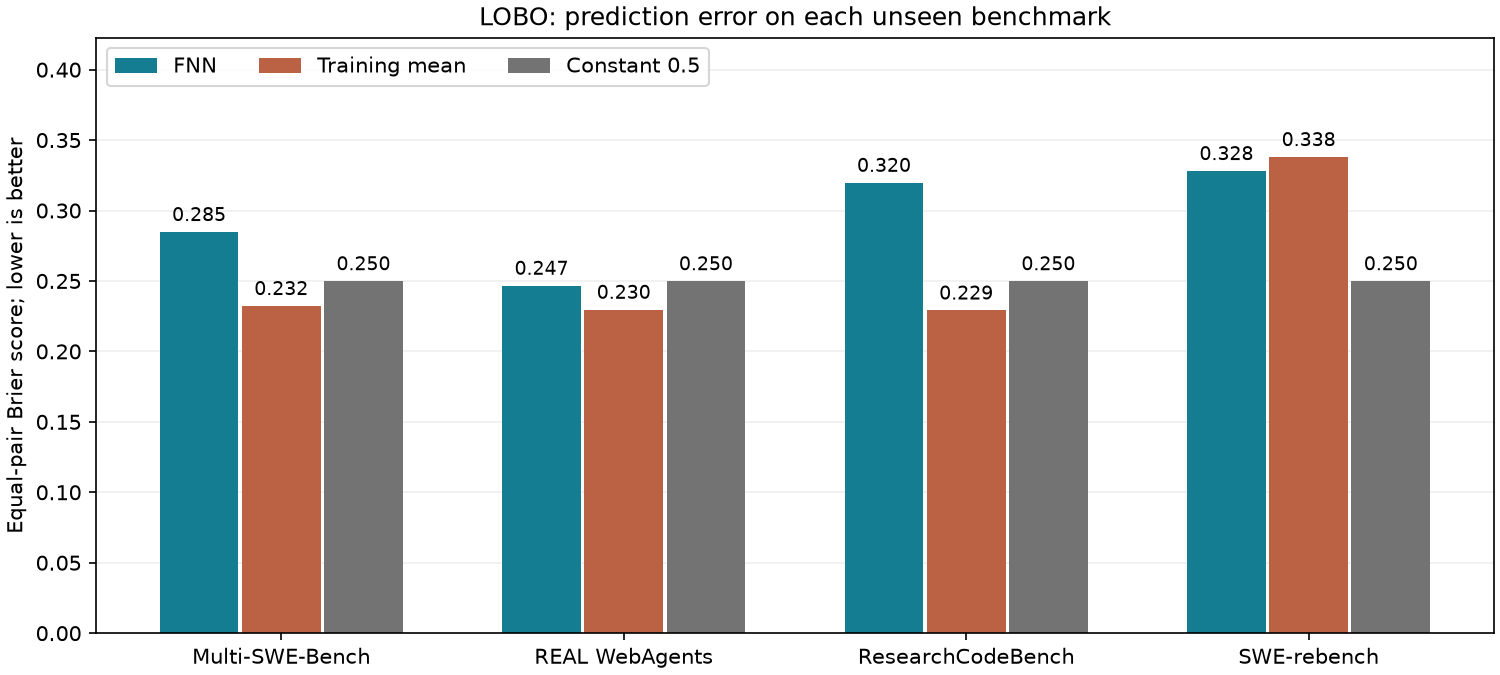

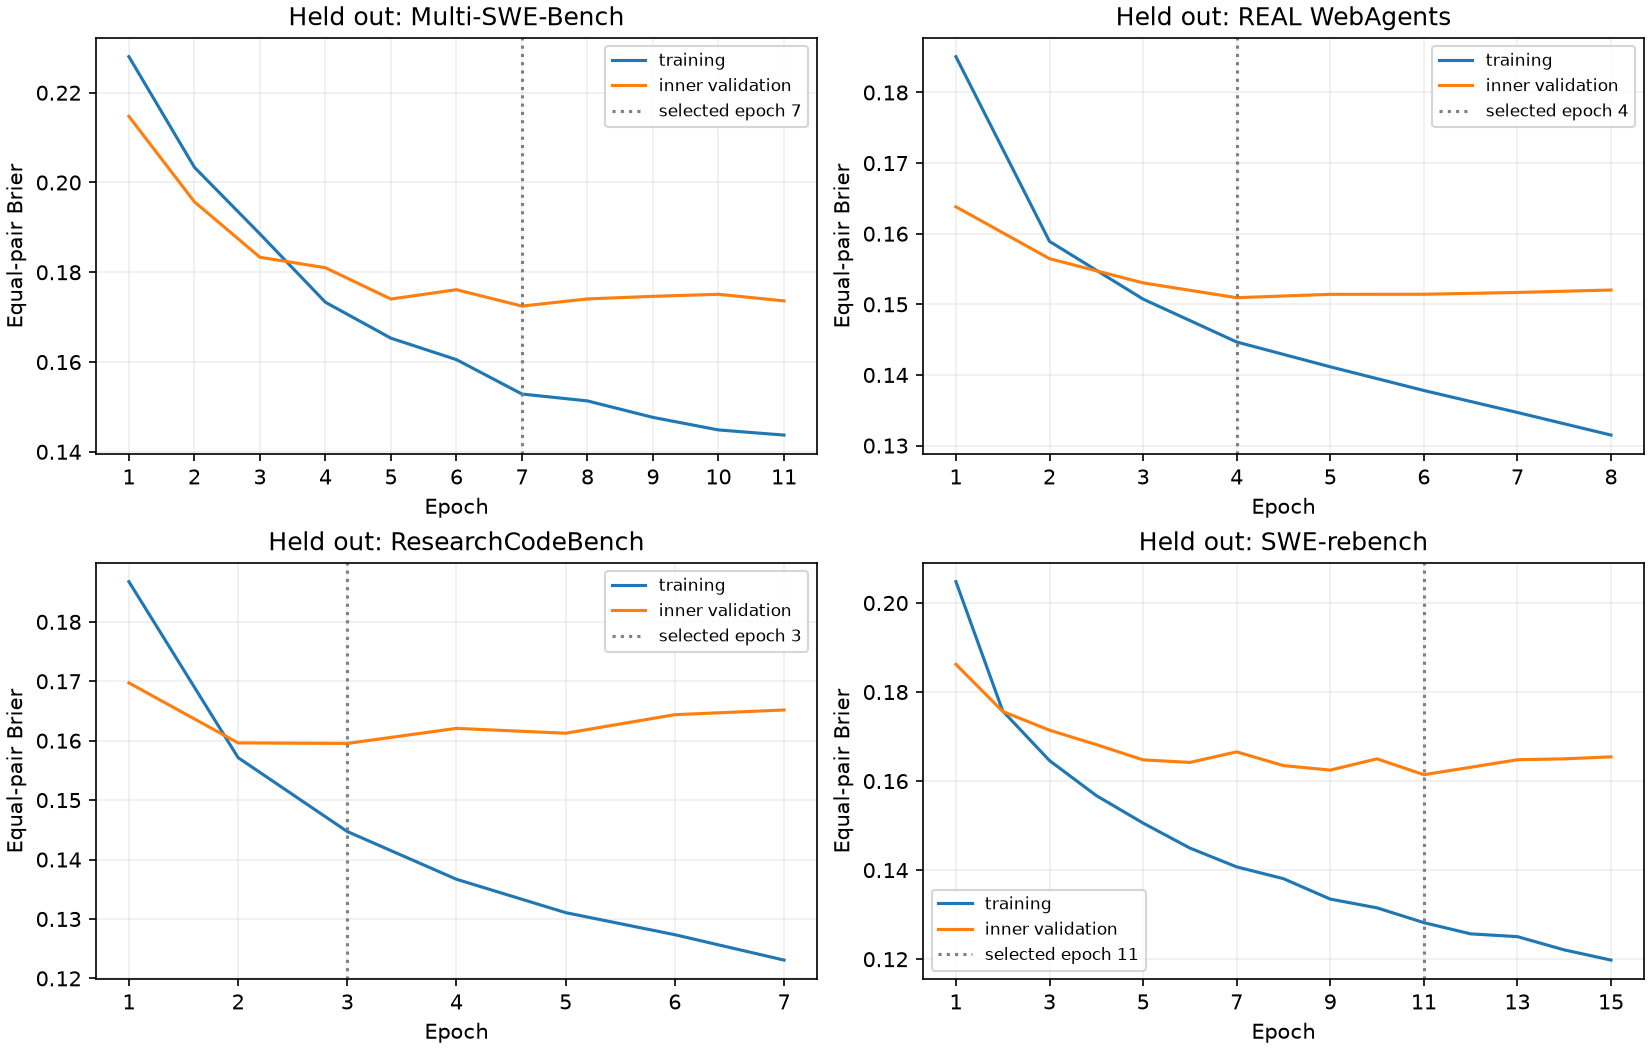

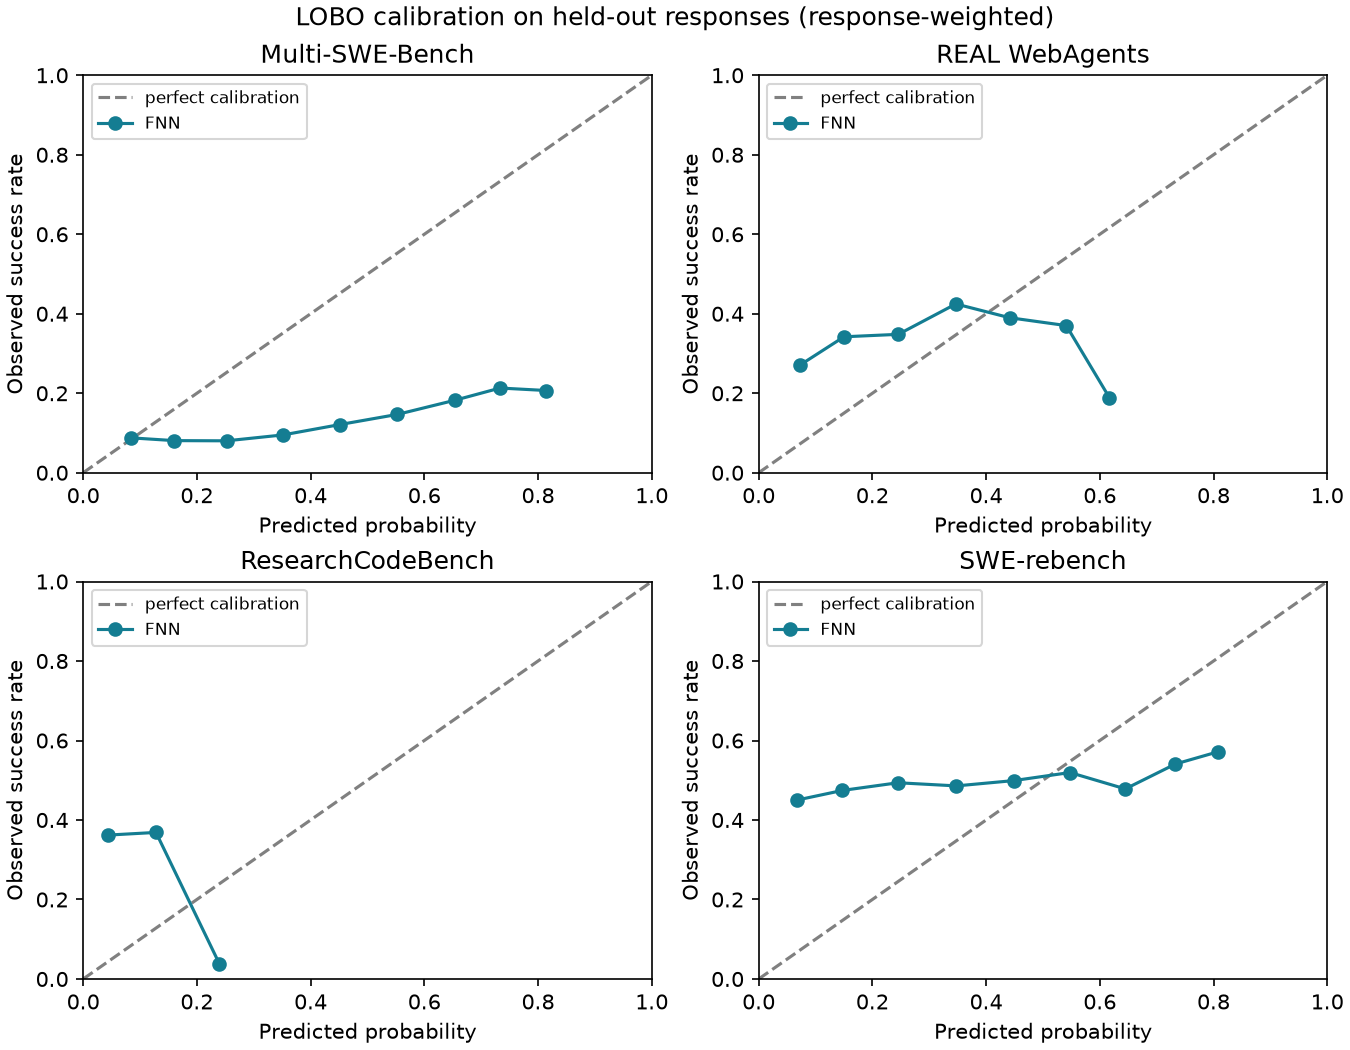

In [7]:
for name in ['lobo_comparison.png', 'lobo_learning_curves.png', 'lobo_calibration.png']:
    display(Image(filename=str(lobo_dir / name)))

### Summary

A short summary of the method and findings for the team report.

In [8]:
from IPython.display import Markdown

display(Markdown((lobo_dir / 'team_summary.md').read_text()))

I ran LOBO on my SBERT FNN across the four binary benchmarks, holding out one benchmark at a time and training from scratch on the others. I kept the task embeddings, model metadata, and text statistics, with hidden layers of 64 and 16 neurons, Brier loss, 35% dropout, and L2 regularization (0.0001). Early stopping used a separate validation split.

The overall equal-pair Brier was 0.2840, compared with 0.2318 for a training-average baseline and 0.2500 for constant 0.5 predictions. The FNN beat the training-average baseline on 1 of 4 benchmarks. The mean across benchmarks was 0.2949. The current model seems to learn the training benchmarks better than it transfers to new ones. These are local results, not CodaBench scores.


## Final full-data training

We now train a fresh FNN on every eligible binary response, using the same features and architecture. The LOBO models selected epochs 7, 4, 3, and 11 using their inner validation sets. Their median is 5.5, rounded to 6 epochs for the final fit. No held-out test scores were used to choose this count.

There is no validation split in this final fit. The curves show training performance only; use the LOBO results above to judge generalization. Set `RUN_FINAL_TRAINING = True` and choose a new run name to train and package another final model.

In [9]:
RUN_FINAL_TRAINING = False
FINAL_RUN_NAME = 'fnn_final_all_binary_20261019_01'

if RUN_FINAL_TRAINING:
    from dharaneesh.experiments import refit_fnn_submission
    refit_fnn_submission(
        DATA_DIR, FINAL_RUN_NAME, lobo_summary_path=lobo_dir / 'summary.json',
        seed=SEED, encoder_dir=ENCODER_DIR
    )

final_dir = REPO / 'dharaneesh/results/final'
final_summary = json.loads((final_dir / 'summary.json').read_text())
final_history = pd.read_csv(final_dir / 'history.csv')
assert final_summary['config']['refit_on_all_public']
assert final_summary['validation_rows'] == 0
print('Training responses:', final_summary['training_rows'])
print('Distinct task prompts:', final_summary['training_prompts'])
print('Fixed epochs:', final_summary['epochs_completed'])
print('Training time:', round(final_summary['training_seconds'], 1), 'seconds')

Training responses: 136282
Distinct task prompts: 8794
Fixed epochs: 6
Training time: 14.6 seconds


Epoch 1: training Brier=0.1915, training accuracy=0.7200
Epoch 2: training Brier=0.1646, training accuracy=0.7533
Epoch 3: training Brier=0.1532, training accuracy=0.7790
Epoch 4: training Brier=0.1476, training accuracy=0.7902
Epoch 5: training Brier=0.1421, training accuracy=0.7986
Epoch 6: training Brier=0.1384, training accuracy=0.8080


,accuracy,brier_score,loss,epoch
0,0.720031,0.191535,0.202380,1
1,0.753279,0.164628,0.173709,2
2,0.778975,0.153212,0.162096,3
3,0.790235,0.147611,0.156554,4
4,0.798580,0.142120,0.151237,5
5,0.808001,0.138421,0.147720,6


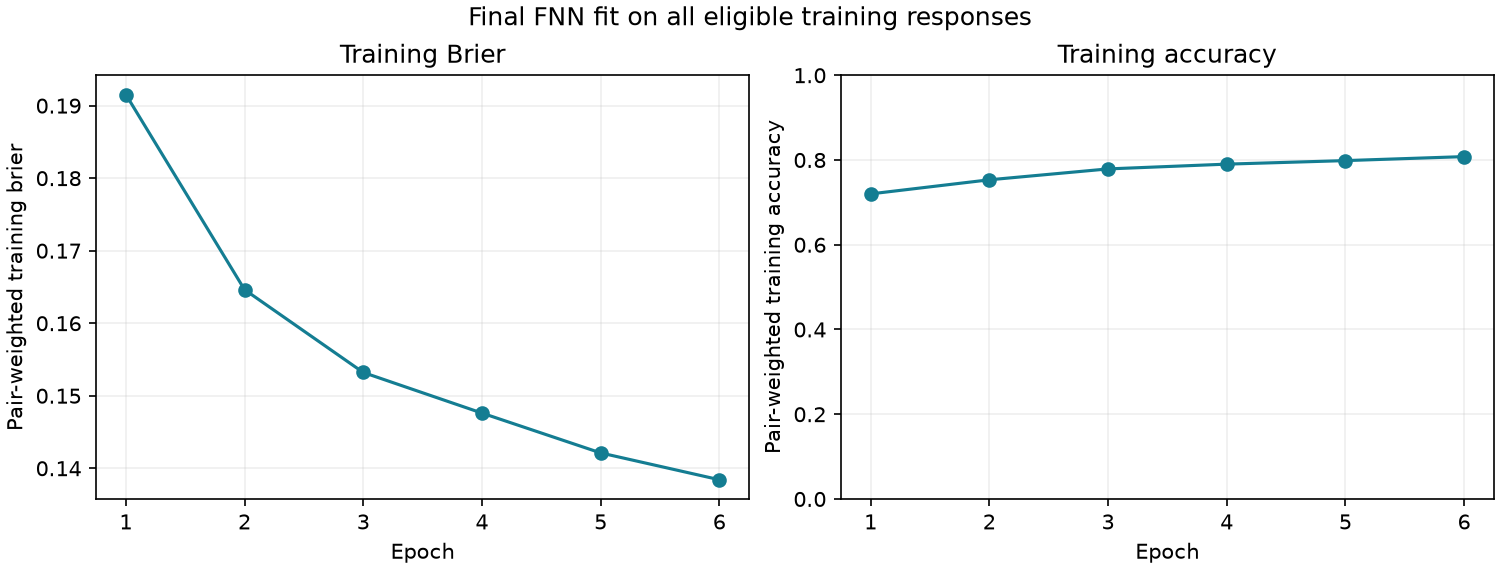

Saved model: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\results\final\final_fnn.keras


In [10]:
for row in final_history.to_dict('records'):
    print(f"Epoch {int(row['epoch'])}: training Brier={row['brier_score']:.4f}, "
          f"training accuracy={row['accuracy']:.4f}")
display(final_history)
display(Image(filename=str(final_dir / 'training.png')))
print('Saved model:', final_dir / 'final_fnn.keras')

## CodaBench submission

Upload `submission_fnn.zip` on CodaBench. It contains the final full-data FNN, prediction code, and SBERT text encoder. The saved Keras model is also available in `results/final/final_fnn.keras`.

In [11]:
import zipfile
from dharaneesh.experiments import package_saved_submission, file_sha256

submission = REPO / 'dharaneesh/submission_fnn.zip'
if REBUILD_ZIP or not submission.is_file():
    submission = package_saved_submission(data_dir=DATA_DIR, encoder_dir=ENCODER_DIR)
with zipfile.ZipFile(submission) as archive:
    assert json.loads(archive.read('config.json')) == final_summary['config']
    assert archive.read('weights.npz') == (REPO / 'dharaneesh/submission/weights.npz').read_bytes()
print('Upload file:', submission)
print('Trained on:', final_summary['training_rows'], 'binary responses')
print('Epochs:', final_summary['epochs_completed'])
print('Size in MB:', round(submission.stat().st_size / 1024**2, 1))
print('SHA-256:', file_sha256(submission))

Upload file: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\submission_fnn.zip
Trained on: 136282 binary responses
Epochs: 6
Size in MB: 79.8
SHA-256: 45da83afcbbfb327871a960d78aeff438e521e3ba44508678d0589891169a652
